# 1. 데이터 불러오기

이 섹션의 목표는 원본 데이터를 분석할 수 있는 표 하나로 정리하는 것입니다.

1. 데이터 폴더 경로를 잡고, 폴더별 파일 개수를 확인합니다.
2. JSON 하나를 열어 실제 형식이 대회 명세와 같은지 확인합니다.
3. 모든 JSON을 읽어 bbox 1개 = 1행인 표(`ann_df`)를 만듭니다.
4. 이미지 파일과 어노테이션의 짝이 맞는지 확인합니다.

데이터 오류를 고치는 작업은 하지 않습니다. 여기서는 어떤 상태인지 세어 보기만 하고, 수정은 이후 섹션(오류 탐지)에서 합니다.

In [77]:
import hashlib
import json
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

# 데이터 폴더 경로 (노트북 위치 기준 상대경로)
DATA_DIR = Path("../data/raw/sprint_ai_project1_data")
TRAIN_IMG_DIR = DATA_DIR / "train_images"
TRAIN_ANN_DIR = DATA_DIR / "train_annotations"
TEST_IMG_DIR = DATA_DIR / "test_images"

# 경로가 틀리면 아래 셀이 전부 0개로 나오므로, 여기서 바로 멈추게 합니다.
assert DATA_DIR.exists(), f"데이터 폴더를 찾을 수 없습니다: {DATA_DIR} (노트북이 notebooks/ 폴더 안에 있는지 확인하세요)"
print("데이터 폴더:", DATA_DIR)

데이터 폴더: ..\data\raw\sprint_ai_project1_data


## 1-1. 대회 제공 데이터 설명

아래 내용은 대회 페이지의 설명을 그대로 옮긴 것입니다. 실제 데이터가 이 설명과 같은지는 이후 단계에서 확인합니다.

### 파일 구성

| 폴더 | 설명 |
|---|---|
| `train_images` | 훈련 데이터(이미지) |
| `train_annotations` | 훈련 데이터(annotation) |
| `test_images` | 테스트 데이터(이미지) |

### JSON 항목

필수 여부의 M, O, C는 명세에 따로 설명이 없습니다. 보통 M은 필수, O는 선택, C는 조건부를 뜻합니다.

#### images: 이미지 정보

| 항목명 | 타입 | 필수 여부 | 설명 |
|---|---|---|---|
| `images` | Object | M | 약제 이미지정보 |
| `images[].id` | Number | M | 약제 이미지식별자 |
| `images[].width` | Number | M | 약제 이미지너비 |
| `images[].height` | Number | M | 약제 이미지높이 |
| `images[].file_name` | String | M | 약제 이미지파일명 |
| `images[].drug_N` | String | M | 알약코드 |
| `images[].drug_S` | String | M | 알약상태 |
| `images[].back_color` | String | M | 촬영배경 |
| `images[].drug_dir` | String | M | 알약방향 |
| `images[].light_color` | String | M | 촬영조명 |
| `images[].camera_la` | Number | M | 카메라위도 |
| `images[].camera_lo` | Number | M | 카메라경도 |
| `images[].size` | Number | M | 이미지 사이즈 |
| `images[].dl_idx` | String | M | 알약 식별자 |
| `images[].dl_mapping_code` | String | M | 제품코드 |
| `images[].dl_name` | String | M | 제품명 |
| `images[].dl_name_en` | String | O | 제품명(영어) |
| `images[].img_key` | String | M | 이미지 링크 |
| `images[].dl_material` | String | M | 성분명 |
| `images[].dl_material_en` | String | O | 성분명(영어) |
| `images[].dl_custom_shape` | String | M | 제조 모양 |
| `images[].dl_company` | String | M | 제조사명 |
| `images[].dl_company_en` | String | O | 제조사명(영어) |
| `images[].di_company_mf` | String | M | 위탁제조사명 |
| `images[].di_company_mf_en` | String | O | 위탁제조사명(영어) |
| `images[].item_seq` | Number | M | 품목기준코드 |
| `images[].di_item_permit_date` | Date | O | 허가일자 |
| `images[].di_class_no` | String | M | 약품 분류 |
| `images[].di_etc_otc_code` | String | M | 전문의약품/일반의약품 |
| `images[].di_edi_code` | String | M | EDI 코드 |
| `images[].chart` | String | M | 알약 제형 |
| `images[].drug_shape` | String | M | 알약 모양 |
| `images[].thick` | Number | M | 알약 두께 |
| `images[].leng_long` | Number | M | 알약 장축 |
| `images[].leng_short` | Number | M | 알약 단축 |
| `images[].print_front` | String | C | 식별문자_앞 |
| `images[].print_back` | String | C | 식별문자_뒤 |
| `images[].color_class1` | String | M | 색상 1 |
| `images[].color_class2` | String | O | 색상 2 |
| `images[].line_front` | String | M | 알약 앞면분할선 여부 |
| `images[].line_back` | String | M | 알약 뒷면분할선 여부 |
| `images[].img_regist_ts` | Date | O | 약학정보원 이미지 생성일 |
| `images[].form_code_name` | String | M | 정제 분류명 |
| `images[].mark_code_front_anal` | String | M | 알약 앞면마크 형태 |
| `images[].mark_code_back_anal` | String | M | 알약 뒷면마크 형태 |
| `images[].mark_code_front_img` | String | M | 알약 앞면마크 이미지 |
| `images[].mark_code_back_img` | String | M | 알약 뒷면마크 이미지 |
| `images[].mark_code_front` | String | M | 알약 앞면마크 코드 |
| `images[].mark_code_back` | String | M | 알약 뒷면마크 코드 |
| `images[].change_date` | Date | O | 변경일자 |

#### annotations: 라벨링 정보

| 항목명 | 타입 | 필수 여부 | 설명 |
|---|---|---|---|
| `annotations` | Object | M | 라벨링정보 |
| `annotations[].area` | Number | M | 바운딩박스 면적 |
| `annotations[].iscrowd` | Number | O | 평가 분류 |
| `annotations[].bbox` | List | M | bbox 좌표 |
| `annotations[].category_id` | Number | M | category 아이디 |
| `annotations[].ignore` | Number | O | 무시 여부 |
| `annotations[].segmentation` | List | O | 라벨링바운딩 박스 |
| `annotations[].image_id` | Number | M | 이미지 아이디 |
| `annotations[].id` | Number | M | 어노테이션 아이디 |

#### categories, type

| 항목명 | 타입 | 필수 여부 | 설명 |
|---|---|---|---|
| `categories` | Object | M | 라이선스 |
| `categories[].supercategory` | String | M | 슈퍼 카테고리 |
| `categories[].id` | Number | M | 카테고리 아이디 |
| `categories[].name` | String | C | 카테고리 명 |
| `type` | type | O | json 타입 |

## 1-2. 데이터 폴더 구조와 파일 개수

데이터 폴더를 세 가지 방법으로 확인합니다.

1. 트리: 폴더가 어떻게 생겼는지 봅니다. 폴더 이름 옆의 숫자는 `[바로 아래 폴더 수 · 그 아래 전체 파일 수]`입니다. 한 폴더 안에서는 앞의 3개 항목만 보여 주고, 나머지는 개수로 요약합니다.
2. 표: 최상위 폴더별로 확장자마다 파일이 몇 개인지 셉니다. png, json이 아닌 파일이 섞여 있으면 여기서 드러납니다.
3. 그래프: 표의 폴더별 합계를 막대로 그립니다.

마지막 셀에서는 이후 분석에 쓸 파일 목록을 만듭니다. `rglob`은 하위 폴더가 몇 단계로 들어 있어도 파일을 모두 찾습니다. 여기서 센 개수가 위 표의 png, json 개수와 같아야 합니다.

In [78]:
def folder_summary(folder):
    """폴더 옆에 붙일 요약: [바로 아래 폴더 수 · 하위 전체 파일 수]"""
    n_dirs = sum(1 for p in folder.iterdir() if p.is_dir())
    n_files = sum(1 for p in folder.rglob("*") if p.is_file())
    return f"[폴더 {n_dirs}개 · 파일 {n_files}개]"


def show_tree(folder, max_depth=4, max_items=3, prefix=""):
    """폴더 구조를 트리 모양으로 출력한다.

    max_depth: 몇 단계 아래까지 펼칠지
    max_items: 한 폴더 안에서 이름을 보여 줄 항목 수 (나머지는 개수로 요약)
    """
    children = sorted(folder.iterdir())
    dirs = [p for p in children if p.is_dir()]
    files = [p for p in children if p.is_file()]

    # 폴더를 먼저, 파일을 나중에 보여 준다.
    shown = (dirs + files)[:max_items]
    hidden_dirs = len(dirs) - sum(p.is_dir() for p in shown)
    hidden_files = len(files) - sum(p.is_file() for p in shown)
    has_hidden = hidden_dirs > 0 or hidden_files > 0

    for i, child in enumerate(shown):
        is_last = (i == len(shown) - 1) and not has_hidden
        branch = "└── " if is_last else "├── "

        if child.is_dir():
            print(f"{prefix}{branch}{child.name}/  {folder_summary(child)}")
            if max_depth > 1:
                # 마지막 항목 아래는 세로줄 없이 들여쓴다.
                next_prefix = prefix + ("    " if is_last else "│   ")
                show_tree(child, max_depth - 1, max_items, next_prefix)
        else:
            print(f"{prefix}{branch}{child.name}")

    if has_hidden:
        rest = []
        if hidden_dirs:
            rest.append(f"폴더 {hidden_dirs}개")
        if hidden_files:
            rest.append(f"파일 {hidden_files}개")
        print(f"{prefix}└── ... 외 {', '.join(rest)}")


print(f"{DATA_DIR.name}/  {folder_summary(DATA_DIR)}")
show_tree(DATA_DIR)

sprint_ai_project1_data/  [폴더 3개 · 파일 1837개]
├── test_images/  [폴더 0개 · 파일 842개]
│   ├── 1.png
│   ├── 10.png
│   ├── 100.png
│   └── ... 외 파일 839개
├── train_annotations/  [폴더 114개 · 파일 763개]
│   ├── K-001900-016548-019607-029451_json/  [폴더 4개 · 파일 12개]
│   │   ├── K-001900/  [폴더 0개 · 파일 3개]
│   │   │   ├── K-001900-016548-019607-029451_0_2_0_2_70_000_200.json
│   │   │   ├── K-001900-016548-019607-029451_0_2_0_2_75_000_200.json
│   │   │   └── K-001900-016548-019607-029451_0_2_0_2_90_000_200.json
│   │   ├── K-016548/  [폴더 0개 · 파일 3개]
│   │   │   ├── K-001900-016548-019607-029451_0_2_0_2_70_000_200.json
│   │   │   ├── K-001900-016548-019607-029451_0_2_0_2_75_000_200.json
│   │   │   └── K-001900-016548-019607-029451_0_2_0_2_90_000_200.json
│   │   ├── K-019607/  [폴더 0개 · 파일 3개]
│   │   │   ├── K-001900-016548-019607-029451_0_2_0_2_70_000_200.json
│   │   │   ├── K-001900-016548-019607-029451_0_2_0_2_75_000_200.json
│   │   │   └── K-001900-016548-019607-029451_0_2_0_2_90_000_200.json

In [79]:
# 최상위 폴더마다 하위의 모든 파일을 확장자별로 셉니다.
records = []
for top in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for p in top.rglob("*"):
        if p.is_file():
            records.append({"folder": top.name, "ext": p.suffix.lower() or "(확장자 없음)"})
file_df = pd.DataFrame(records)

# margins=True: 마지막 행과 열에 합계를 붙입니다.
count_df = pd.crosstab(file_df["folder"], file_df["ext"], margins=True, margins_name="합계")
count_df

ext,.json,.png,합계
folder,,,
test_images,0,842,842
train_annotations,763,0,763
train_images,0,232,232
합계,763,1074,1837


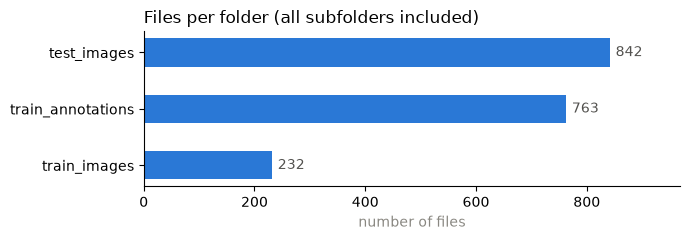

In [80]:
# 폴더별 전체 파일 수를 막대그래프로 그립니다. (마지막 '합계' 행은 제외)
totals = count_df["합계"].drop("합계").sort_values()

fig, ax = plt.subplots(figsize=(7, 2.5))
bars = ax.barh(totals.index, totals.values, height=0.5, color="#2a78d6")

# 막대 끝에 개수를 적습니다.
ax.bar_label(bars, padding=4, color="#52514e")

# 그래프 안 글자는 영어로 둡니다. matplotlib 기본 글꼴에는 한글이 없어서 한글이 네모로 깨집니다.
ax.set_title("Files per folder (all subfolders included)", loc="left")
ax.set_xlabel("number of files", color="#898781")
ax.set_xlim(0, totals.max() * 1.15)  # 막대 끝 숫자가 잘리지 않도록 여유를 둡니다.
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

In [81]:
train_img_paths = sorted(TRAIN_IMG_DIR.rglob("*.png"))
test_img_paths = sorted(TEST_IMG_DIR.rglob("*.png"))
ann_paths = sorted(TRAIN_ANN_DIR.rglob("*.json"))

print(f"train 이미지 : {len(train_img_paths)}장")
print(f"test 이미지  : {len(test_img_paths)}장")
print(f"train JSON   : {len(ann_paths)}개")

train 이미지 : 232장
test 이미지  : 842장
train JSON   : 763개


## 1-3. JSON 읽기

모든 JSON을 한 번씩 읽어 `loaded` 리스트에 `(경로, 내용)` 형태로 담아 둡니다. 이후 셀은 파일을 다시 열지 않고 이 리스트를 씁니다.

- Windows에서 인코딩을 지정하지 않고 열면 기본값(cp949)으로 읽어 한글 때문에 오류가 납니다. 그래서 UTF-8로 엽니다.
- 읽다가 오류가 난 파일은 멈추지 않고 `failed_paths`에 모아 둡니다.

In [82]:
def read_json(path):
    """JSON 파일 하나를 읽어 dict로 돌려준다. 읽지 못하면 None을 돌려준다."""
    try:
        # utf-8-sig: 파일 맨 앞에 BOM이 있어도, 없어도 읽을 수 있는 UTF-8 방식
        with open(path, encoding="utf-8-sig") as f:
            return json.load(f)
    except (OSError, UnicodeDecodeError, json.JSONDecodeError) as e:
        print(f"[읽기 실패] {path.name}: {e}")
        return None


loaded = []        # (경로, JSON 내용) 목록
failed_paths = []  # 읽지 못한 파일 목록

for path in ann_paths:
    data = read_json(path)
    if data is None:
        failed_paths.append(path)
    else:
        loaded.append((path, data))

print(f"읽기 성공: {len(loaded)}개 / 실패: {len(failed_paths)}개")

읽기 성공: 763개 / 실패: 0개


## 1-4. JSON 하나 열어 보기

대회 명세에 따르면 JSON은 `images`, `annotations`, `categories`와 선택 항목인 `type`으로 되어 있습니다.
첫 번째 파일을 열어 실제 형식이 명세와 같은지 눈으로 확인합니다.

In [83]:
sample_path, sample = loaded[0]

print("파일:", sample_path.relative_to(TRAIN_ANN_DIR))
print("최상위 키:", list(sample.keys()))
print()

# annotations, categories는 항목이 적어서 전체를 출력합니다.
# ensure_ascii=False: 한글을 \uXXXX가 아닌 글자 그대로 출력
print("[annotations]")
print(json.dumps(sample.get("annotations"), ensure_ascii=False, indent=2))
print("[categories]")
print(json.dumps(sample.get("categories"), ensure_ascii=False, indent=2))

# images는 항목이 많아서, 이번 분석에 쓰는 항목만 출력합니다.
print("[images[0] 주요 항목]")
sample_img = (sample.get("images") or [{}])[0]  # images가 비어 있어도 오류가 나지 않게
for key in ["file_name", "width", "height", "dl_idx", "dl_name"]:
    print(f"  {key}: {sample_img.get(key)}")

파일: K-001900-016548-019607-029451_json\K-001900\K-001900-016548-019607-029451_0_2_0_2_70_000_200.json
최상위 키: ['images', 'type', 'annotations', 'categories']

[annotations]
[
  {
    "area": 35910,
    "iscrowd": 0,
    "bbox": [
      644,
      845,
      189,
      190
    ],
    "category_id": 1900,
    "ignore": 0,
    "segmentation": [],
    "id": 133,
    "image_id": 34
  }
]
[categories]
[
  {
    "supercategory": "pill",
    "id": 1900,
    "name": "보령부스파정 5mg"
  }
]
[images[0] 주요 항목]
  file_name: K-001900-016548-019607-029451_0_2_0_2_70_000_200.png
  width: 976
  height: 1280
  dl_idx: 1900
  dl_name: 보령부스파정 5mg


## 1-5. 전체 JSON 구조 확인

파일 개수를 보면 "JSON 1개 = 알약 1개" 구조로 추정됩니다(이미지 1장당 JSON 평균 3.3개).
모든 JSON이 정말 "이미지 1개 + 어노테이션 1개"인지, `(images 개수, annotations 개수)` 조합별로 파일 수를 세어 확인합니다.

In [84]:
structure = Counter(
    (len(data.get("images", [])), len(data.get("annotations", [])))
    for _, data in loaded
)

for (n_img, n_ann), count in sorted(structure.items()):
    print(f"images {n_img}개 + annotations {n_ann}개 → JSON {count}개")

images 1개 + annotations 1개 → JSON 763개


## 1-6. 어노테이션 표 만들기

모든 JSON을 bbox 1개 = 1행인 표 `ann_df`로 정리합니다. 이후 EDA 섹션은 모두 이 표를 사용합니다.

| 열 | 출처 | 설명 |
|---|---|---|
| `json_path` | 파일 경로 | 문제가 있는 행의 원본 파일을 찾을 때 사용 |
| `file_name`, `img_width`, `img_height` | `images[0]` | 이미지 파일명과 크기 |
| `category_id` | `annotations[]` | 클래스 번호 (제출 파일에 쓰는 값) |
| `dl_idx`, `dl_name` | `images[0]` | 알약 식별자와 약 이름 |
| `bbox_x`, `bbox_y`, `bbox_w`, `bbox_h` | `annotations[].bbox` | 좌상단 x, y와 너비, 높이 (픽셀) |
| `bbox_ok` | 계산 | bbox가 명세의 유효 기준(값 4개짜리 리스트)을 만족하는지 |

명세상 `category_id`는 `dl_idx` 값으로 만들었다고 되어 있습니다. 둘이 실제로 같은지는 오류 탐지 섹션에서 비교하려고 두 열을 모두 남겨 둡니다.

In [85]:
def to_rows(path, data):
    """JSON 하나를 표의 행 목록으로 바꾼다. 어노테이션 1개가 1행이 된다."""
    images = data.get("images", [])
    img = images[0] if images else {}  # 명세상 JSON 하나에 이미지 정보는 1개

    rows = []
    for ann in data.get("annotations", []):
        bbox = ann.get("bbox")
        # 명세의 유효 기준: 리스트이고 길이가 정확히 4 ([x, y, w, h])
        bbox_ok = isinstance(bbox, list) and len(bbox) == 4
        x, y, w, h = bbox if bbox_ok else (None, None, None, None)

        rows.append({
            "json_path": path.relative_to(TRAIN_ANN_DIR).as_posix(),
            "file_name": img.get("file_name"),
            "img_width": img.get("width"),
            "img_height": img.get("height"),
            "category_id": ann.get("category_id"),
            "dl_idx": img.get("dl_idx"),
            "dl_name": img.get("dl_name"),
            "bbox_x": x,
            "bbox_y": y,
            "bbox_w": w,
            "bbox_h": h,
            "bbox_ok": bbox_ok,
        })
    return rows


rows = []
for path, data in loaded:
    rows.extend(to_rows(path, data))
ann_df = pd.DataFrame(rows)

print(f"표 크기: {ann_df.shape[0]}행 x {ann_df.shape[1]}열")
print(f"bbox 유효: {ann_df['bbox_ok'].sum()}개 / 유효하지 않음: {(~ann_df['bbox_ok']).sum()}개")
ann_df.head()

표 크기: 763행 x 12열
bbox 유효: 763개 / 유효하지 않음: 0개


,json_path,file_name,img_width,img_height,category_id,dl_idx,dl_name,bbox_x,bbox_y,bbox_w,bbox_h,bbox_ok
0,K-001900-016548-019607-029451_json/K-001900/K-...,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,1900,1900,보령부스파정 5mg,644,845,189,190,True
1,K-001900-016548-019607-029451_json/K-001900/K-...,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,1900,1900,보령부스파정 5mg,148,241,181,181,True
2,K-001900-016548-019607-029451_json/K-001900/K-...,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,976,1280,1900,1900,보령부스파정 5mg,167,248,184,182,True
3,K-001900-016548-019607-029451_json/K-016548/K-...,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,16548,16548,가바토파정 100mg,144,799,239,239,True
4,K-001900-016548-019607-029451_json/K-016548/K-...,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,16548,16548,가바토파정 100mg,578,222,233,226,True


## 1-7. 이미지와 어노테이션 짝 확인

이미지 파일명과 JSON 안의 `file_name`을 비교합니다.

- 어노테이션이 없는 이미지: 학습에 쓰면 모델이 그 안의 알약을 "배경"으로 배웁니다.
- 이미지 파일이 없는 어노테이션: 학습에 쓸 수 없는 라벨입니다.

In [86]:
train_names = {p.name for p in train_img_paths}
ann_names = set(ann_df["file_name"].dropna())

# 하위 폴더에 같은 이름의 이미지가 있으면 파일명만으로는 구분이 안 되므로 미리 확인합니다.
if len(train_names) != len(train_img_paths):
    print(f"[주의] 파일명이 겹치는 이미지가 있습니다: {len(train_img_paths) - len(train_names)}개")

no_ann_images = sorted(train_names - ann_names)  # 이미지는 있는데 어노테이션이 없음
no_image_anns = sorted(ann_names - train_names)  # 어노테이션은 있는데 이미지 파일이 없음

print(f"어노테이션이 있는 이미지      : {len(train_names & ann_names)}장 / 전체 {len(train_names)}장")
print(f"어노테이션이 없는 이미지      : {len(no_ann_images)}장")
print(f"이미지 파일이 없는 어노테이션 : {len(no_image_anns)}개 (파일명 기준)")

# 해당하는 항목이 있으면 앞의 5개만 보여 줍니다.
if no_ann_images:
    print("  예시(어노테이션 없음):", no_ann_images[:5])
if no_image_anns:
    print("  예시(이미지 없음):", no_image_anns[:5])

어노테이션이 있는 이미지      : 232장 / 전체 232장
어노테이션이 없는 이미지      : 0장
이미지 파일이 없는 어노테이션 : 0개 (파일명 기준)


## 1-8. 정리

- 파일 구성: train 이미지 232장, test 이미지 842장, train JSON 763개입니다. 트리, 표, rglob 개수가 모두 같고, png와 json 외의 파일은 없습니다.
- 폴더 구조: `train_annotations/조합 폴더(114개)/알약 코드 폴더/이미지별 JSON`입니다. 조합 폴더 이름과 이미지 파일명 앞부분에 그 사진에 들어 있는 알약 코드가 적혀 있습니다.
- JSON 형식: 대회 명세와 같습니다(`images`, `type`, `annotations`, `categories`). 763개 모두 문제없이 읽혔습니다.
- JSON 구조: 763개 전부 "이미지 1개 + 어노테이션 1개"입니다. 즉 JSON 1개가 알약 1개입니다.
- bbox: 763개 모두 값 4개짜리로 형식은 유효합니다. 값이 이미지 안에 있는지는 아직 확인하지 않았습니다.
- 짝 확인: 232장 모두 어노테이션이 있고, 이미지 파일이 없는 어노테이션도 없습니다.
- 이미지당 어노테이션은 평균 3.3개입니다. 파일명의 알약 코드 수와 비교하면 라벨이 빠진 알약을 찾을 수 있습니다.

다음 섹션부터는 `ann_df` 표를 사용합니다.

# 2. 샘플 이미지 보기

train, test 이미지에서 각각 6장을 무작위로 골라 원본 그대로 봅니다. bbox는 그리지 않고, 사진 자체가 어떻게 생겼는지(배경, 조명, 알약 개수와 배치)를 확인하는 용도입니다.

- 무작위 추출에 seed를 고정해서, 다시 실행해도 팀원이 실행해도 같은 사진이 뽑힙니다. 다른 사진을 보고 싶으면 `seed` 값을 바꿉니다.
- 사진 위에는 파일명, 크기(가로x세로), 색 모드를 적습니다. 색 모드는 `RGB`(3채널), `RGBA`(투명도 포함 4채널), `L`(흑백) 등이 있으며, 모델에 넣기 전에 채널 수를 맞춰야 하는지 판단하는 데 씁니다.
- 그래프 안 글자는 1-2와 같은 이유로 영어로 둡니다.

In [87]:
def show_samples(img_paths, title, n=6, seed=42, ncols=3):
    """이미지 목록에서 n장을 무작위로 골라 격자로 보여 준다.

    seed가 같으면 항상 같은 사진이 뽑힌다.
    random.Random(seed)는 이 함수 안에서만 쓰는 난수 생성기라서, 노트북의 다른 난수에 영향을 주지 않는다.
    """
    picked = random.Random(seed).sample(img_paths, n)
    nrows = (n + ncols - 1) // ncols  # 올림 나눗셈: 6장을 3열로 놓으면 2행

    # 원본 사진이 세로로 긴 편(976x1280)이라 칸도 세로로 길게 잡습니다.
    # layout="constrained": 전체 제목과 사진별 제목이 겹치지 않게 자동으로 간격을 맞춥니다.
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 5.5 * nrows), layout="constrained")

    # 사진 칸의 눈금을 모두 끕니다. 칸이 사진 수보다 많으면 남는 칸은 빈칸으로 보입니다.
    for ax in axes.flat:
        ax.axis("off")

    for ax, path in zip(axes.flat, picked):
        # with 문: 이미지를 다 쓰면 파일을 바로 닫습니다.
        with Image.open(path) as img:
            ax.imshow(img)
            ax.set_title(f"{path.name}\n{img.width}x{img.height}, {img.mode}", fontsize=8)

    fig.suptitle(f"{title}: {n} random samples (seed={seed})", x=0.01, ha="left")
    plt.show()

## 2-1. train 이미지

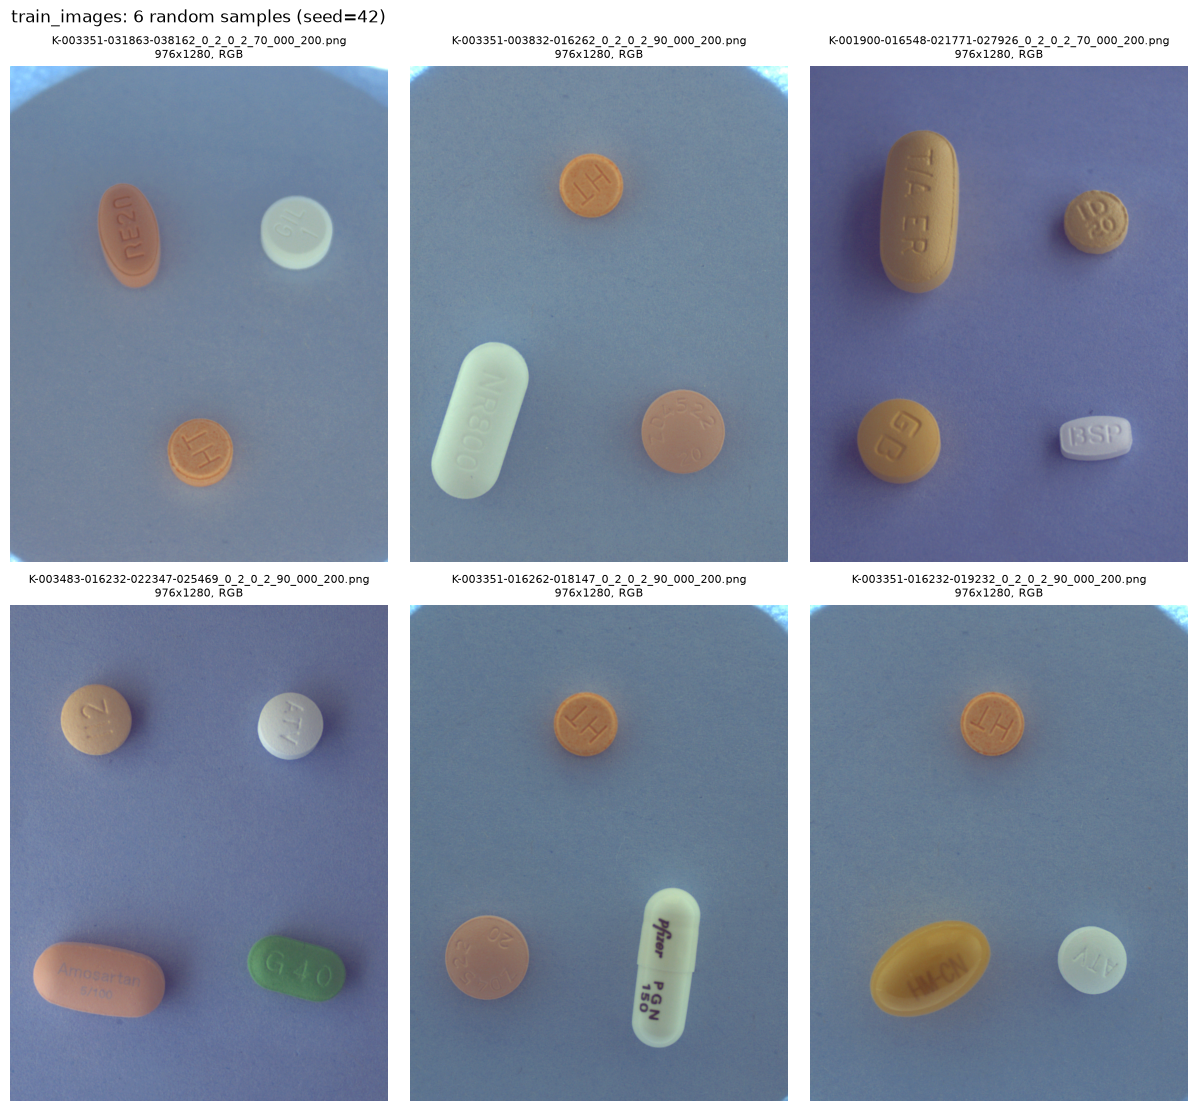

In [88]:
show_samples(train_img_paths, "train_images")

## 2-2. test 이미지

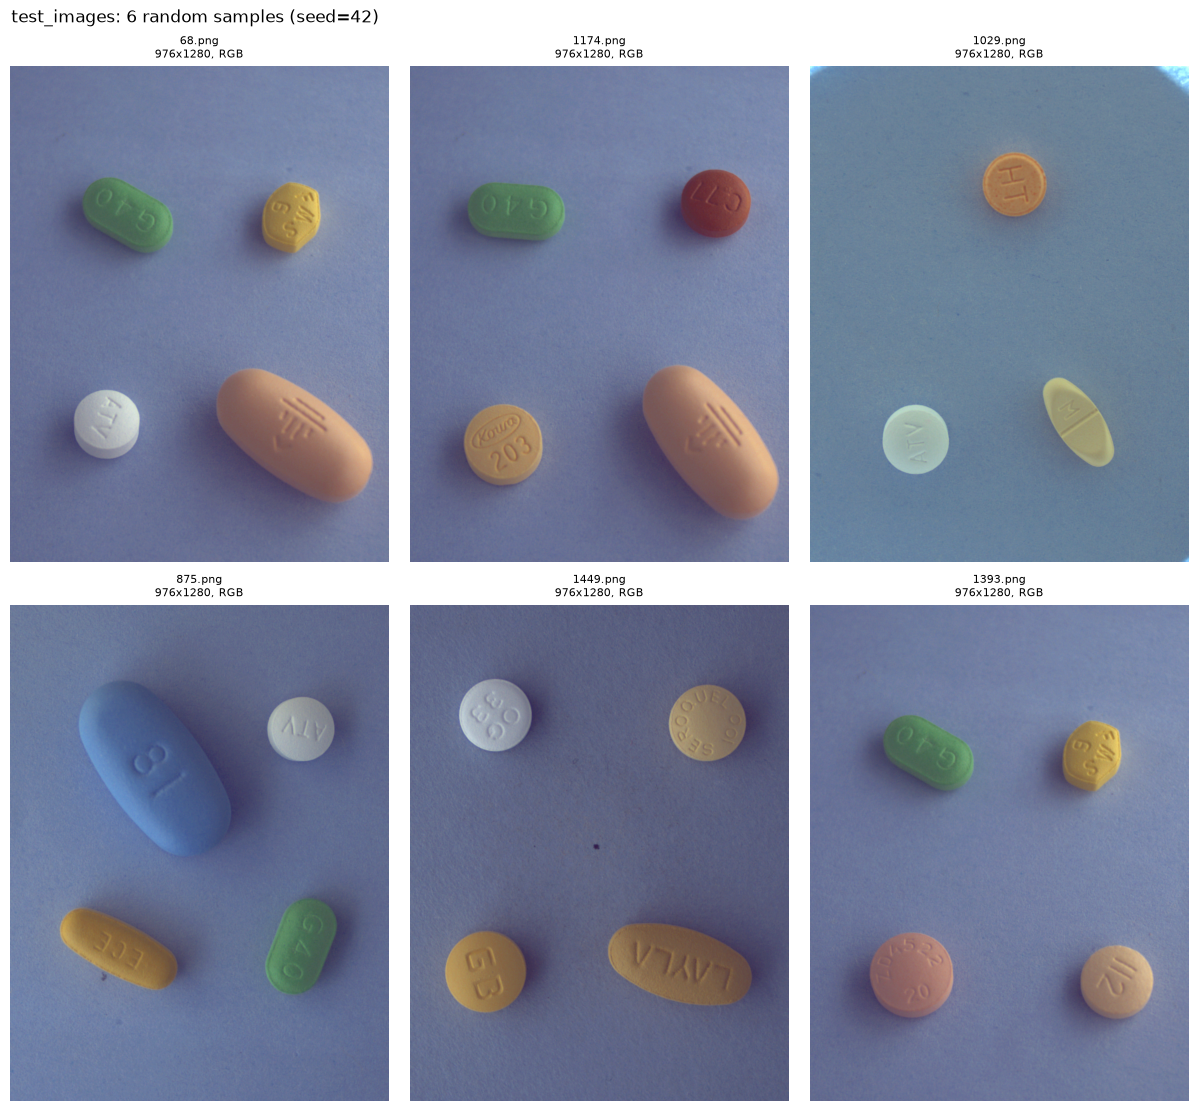

In [89]:
show_samples(test_img_paths, "test_images")

## 2-3. 정리

seed=42로 뽑은 train 6장, test 6장을 본 결과입니다.

- 크기와 색 모드: 12장 모두 976x1280, RGB입니다. 전체 이미지가 모두 같은지는 따로 확인이 필요합니다.
- 배경과 조명: 배경은 모두 연한 청회색 계열이고, 사진마다 밝기와 색감이 조금씩 다릅니다. 일부 사진은 모서리가 밝게 번져 원형 테두리가 보입니다.
- 알약 개수와 배치: 사진마다 알약이 3개 또는 4개이고, 서로 떨어져 놓여 있습니다. 겹치거나 가장자리에 걸친 알약은 없었습니다.
- 파일명 앞부분의 코드: `K-` 뒤의 6자리 숫자는 알약 종류를 나타내는 코드로 추정합니다. 근거는 다음과 같습니다.
    - 같은 알약이 보이는 사진들의 파일명에는 같은 코드가 들어 있었습니다.
    - 파일명에 있는 코드의 종류 수가 사진에 보이는 알약 수와 같았습니다.
    - 근거의 범위: 위 샘플과 별도로, `train_images` 폴더에서 파일명과 이미지를 대조하며 눈으로 살펴본 결과입니다.
- train과 test: 배경, 조명, 알약 크기가 비슷해 보입니다. 같은 알약(주황색 원형 "HT")이 여러 사진에 반복해서 나옵니다.
- 노이즈: test `1449.png` 가운데에 먼지로 보이는 작은 점이 있습니다.

# 3. 중복 이미지

train, test 이미지 1074장 중에 완전히 같은 이미지가 있는지 확인합니다. 중복을 찾기만 하고 지우지는 않습니다.

- 같은 이미지의 기준: 크기, 색 모드, 모든 픽셀 값이 같은 이미지입니다. 파일 내용(바이트)이 아니라 픽셀로 비교하므로, 같은 사진을 다른 이름이나 다른 압축 방식으로 다시 저장한 경우도 찾습니다.
- 살짝 다르게 찍은 사진은 증강 목적으로 넣었을 수 있어서 이번에는 찾지 않습니다.

## 3-1. 이미지 해시값 계산

이미지마다 MD5 해시 함수로 해시값을 계산합니다. 해시 함수에는 이미지의 색 모드, 크기, 압축을 푼 픽셀 값 전체를 넣습니다. 픽셀이 하나라도 다르면 해시값이 사실상 항상 달라지므로, 해시값이 같은 이미지를 같은 이미지로 봅니다.

1074장을 모두 열기 때문에 실행에 시간이 조금 걸립니다.

### 용어 설명

- 해시 함수: 어떤 데이터를 넣든 정해진 길이의 값을 돌려주는 함수입니다. 같은 데이터를 넣으면 항상 같은 값이 나오고, 데이터가 조금만 달라도 전혀 다른 값이 나옵니다.
- 해시값: 해시 함수가 돌려준 값입니다. 데이터 전체를 비교하는 대신 이 값만 비교해서 두 데이터가 같은지 판단할 수 있습니다.
- MD5: 해시 함수의 한 종류입니다. 입력 크기와 상관없이 128비트, 즉 16진수 32글자의 해시값을 만듭니다. 예를 들어 빈 데이터의 MD5 해시값은 `d41d8cd98f00b204e9800998ecf8427e`입니다.

In [90]:
def pixel_hash(path):
    """이미지의 색 모드, 크기, 픽셀 값으로 MD5 해시값을 계산한다."""
    with Image.open(path) as img:
        h = hashlib.md5()  # MD5 해시 계산기를 만든다.
        # update: 해시 계산기에 데이터를 넣는다. 여러 번 넣으면 넣은 데이터를 이어 붙인 전체의 해시값이 된다.
        # 크기와 색 모드도 함께 넣어서, 픽셀 바이트가 우연히 같아도 크기나 색 모드가 다르면 다른 이미지로 본다.
        h.update(f"{img.mode}_{img.width}x{img.height}".encode())
        h.update(img.tobytes())  # 압축을 푼 픽셀 값 전체
        return h.hexdigest()     # 해시값을 16진수 32글자 문자열로 돌려준다.


hash_records = []
for split, paths in [("train", train_img_paths), ("test", test_img_paths)]:
    for path in paths:
        hash_records.append({"split": split, "file_name": path.name, "hash": pixel_hash(path)})
hash_df = pd.DataFrame(hash_records)

print(f"해시값을 계산한 이미지 : {len(hash_df)}장")
print(f"서로 다른 해시값       : {hash_df['hash'].nunique()}개")

해시값을 계산한 이미지 : 1074장
서로 다른 해시값       : 1074개


## 3-2. 중복 묶음 개수

해시값이 같은 이미지끼리 하나의 묶음으로 보고, 묶음을 세 종류로 나눠 셉니다.

- train 안: train 이미지끼리 같은 경우
- test 안: test 이미지끼리 같은 경우
- train-test 사이: 묶음 안에 train과 test 이미지가 함께 있는 경우

In [91]:
# 같은 해시값이 2장 이상인 이미지만 남깁니다. keep=False: 중복된 이미지를 모두 남김
dup_df = hash_df[hash_df.duplicated("hash", keep=False)]

# 묶음(해시값)마다 train, test 이미지가 각각 몇 장인지 셉니다.
# True/False 열을 만들어 더하면 True의 개수가 됩니다.
group_df = (
    dup_df.assign(is_train=dup_df["split"] == "train", is_test=dup_df["split"] == "test")
    .groupby("hash")
    .agg(n_train=("is_train", "sum"), n_test=("is_test", "sum"))
)
# 중복이 0개면 표가 비어서 개수 열의 자료형(dtype)이 숫자로 정해지지 않을 수 있으므로, 정수형(int)으로 변환합니다.
group_df = group_df.astype({"n_train": int, "n_test": int})
group_df["n_images"] = group_df["n_train"] + group_df["n_test"]

# 묶음의 종류를 정합니다.
group_df["kind"] = "train-test 사이"
group_df.loc[group_df["n_test"] == 0, "kind"] = "train 안"
group_df.loc[group_df["n_train"] == 0, "kind"] = "test 안"

print(f"중복 묶음: {len(group_df)}개 (묶음에 속한 이미지 {len(dup_df)}장)")

# 종류별 묶음 수와 이미지 수. 해당하는 묶음이 없는 종류도 0으로 보여 줍니다.
KINDS = ["train-test 사이", "train 안", "test 안"]
summary_df = pd.DataFrame(
    {
        "묶음_수": [int((group_df["kind"] == kind).sum()) for kind in KINDS],
        "이미지_수": [int(group_df.loc[group_df["kind"] == kind, "n_images"].sum()) for kind in KINDS],
    },
    index=pd.Index(KINDS, name="kind"),
)
summary_df

중복 묶음: 0개 (묶음에 속한 이미지 0장)


,묶음_수,이미지_수
kind,,
train-test 사이,0,0
train 안,0,0
test 안,0,0


## 3-3. 정리

위 출력에서 확인할 것:

- 완전히 같은 이미지가 있는가, 있다면 어느 종류(train 안, test 안, train-test 사이)인가
- 3-4 그림에서 같은 묶음의 사진이 정말 같은 사진으로 보이는가

# 4. 이미지당 어노테이션 수와 라벨 누락

train 이미지 232장마다 어노테이션이 몇 개인지 세고, 라벨이 빠진 사진이 있는지 확인합니다. 3번에서 찾은 중복 이미지는 지우지 않은 상태로 셉니다.

라벨 누락 여부는 아래 순서로 판단합니다.

1. 파일명에서 알약 코드를 뽑고, 어노테이션의 `category_id`가 그 코드 안에 있는지 봅니다. "파일명의 코드가 사진 속 알약 종류를 뜻한다"는 가설의 근거를 보는 단계입니다.
2. 이미지마다 파일명 코드와 어노테이션을 비교해서, 차이가 나는 사진을 후보로 뽑습니다.
3. 후보 사진에 bbox를 그려서, 박스가 없는 알약이 있는지 눈으로 확인합니다.
4. 차이가 없던 사진도 몇 장 골라 같은 방식으로 확인합니다. 파일명 자체가 사진과 다른 경우는 2번 비교로 찾을 수 없기 때문입니다.

## 4-1. 이미지당 어노테이션 수

어노테이션이 1개, 2개, 3개, ... 인 이미지가 각각 몇 장인지 셉니다.

어노테이션 수
0      0
1      0
2      7
3    151
4     74
합계: 이미지 232장, 어노테이션 763개


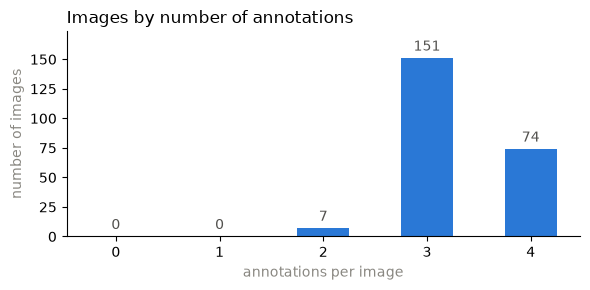

In [92]:
# 이미지마다 어노테이션 수를 셉니다. (ann_df는 bbox 1개 = 1행)
ann_count = ann_df.groupby("file_name").size()

# 전체 train 이미지 목록 기준으로 맞춰서, 어노테이션이 없는 이미지가 있으면 0개로 셉니다.
ann_count = ann_count.reindex([p.name for p in train_img_paths], fill_value=0)

# 0개부터 최대 개수까지 모두 표시합니다. 해당하는 이미지가 없는 개수도 0장으로 보여서 빈 구간이 드러납니다.
dist = ann_count.value_counts().reindex(range(ann_count.max() + 1), fill_value=0)
print(dist.rename_axis("어노테이션 수").rename("이미지 수").to_string())
print(f"합계: 이미지 {dist.sum()}장, 어노테이션 {ann_count.sum()}개")

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(dist.index.astype(str), dist.values, width=0.5, color="#2a78d6")
ax.bar_label(bars, padding=3, color="#52514e")

ax.set_title("Images by number of annotations", loc="left")
ax.set_xlabel("annotations per image", color="#898781")
ax.set_ylabel("number of images", color="#898781")
ax.set_ylim(0, dist.max() * 1.15)  # 막대 위 숫자가 잘리지 않도록 여유를 둡니다.
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

## 4-2. 파일명에서 알약 코드 뽑기

train 파일명은 `K-001900-016548-019607-029451_0_2_0_2_70_000_200.png`처럼 생겼습니다. 첫 번째 `_` 앞부분을 `-`로 나누면 `K` 뒤에 숫자 조각이 남습니다. 이 조각을 알약 코드로 보고, 앞의 0을 뺀 숫자로 바꿉니다(`001900` → `1900`).

이 해석은 가설입니다. 아래 출력으로 판단합니다.

- 나눈 결과 표: 파일명이 의도대로 나뉘었는지 봅니다.
- 파일명의 코드 수: 코드가 몇 개인 파일이 각각 몇 장인지 셉니다.
- `category_id`가 파일명 코드 안에 있는지: 어노테이션마다 확인합니다. 모두 들어 있으면 가설을 뒷받침하는 근거가 되지만, 파일명에 적힌 약이 사진에 실제로 있는지까지 보장하지는 않습니다.

In [93]:
def codes_from_name(file_name):
    """파일명 앞부분의 알약 코드를 숫자 목록으로 바꾼다.

    예: "K-001900-016548-019607-029451_0_2_..." -> [1900, 16548, 19607, 29451]
    형식이 예상과 다르면 빈 목록을 돌려준다.
    """
    head = file_name.split("_")[0]   # "K-001900-016548-019607-029451"
    parts = head.split("-")          # ["K", "001900", "016548", "019607", "029451"]
    if parts[0] != "K" or not all(p.isdigit() for p in parts[1:]):
        return []
    return [int(p) for p in parts[1:]]  # int("001900") -> 1900 (앞의 0이 빠짐)


# 이미지 1장 = 1행인 표를 만듭니다.
img_df = pd.DataFrame({"file_name": [p.name for p in train_img_paths]})
img_df["codes"] = img_df["file_name"].apply(codes_from_name)
img_df["n_codes"] = img_df["codes"].apply(len)

# 형식이 예상과 달라서 코드를 뽑지 못한 파일
bad_names = img_df[img_df["n_codes"] == 0]
print(f"코드를 뽑지 못한 파일명: {len(bad_names)}개")
if len(bad_names):
    print("  예시:", bad_names["file_name"].head().tolist())

print()
print(img_df["n_codes"].value_counts().sort_index().rename_axis("파일명의 코드 수").rename("이미지 수").to_string())

img_df.head()

코드를 뽑지 못한 파일명: 0개

파일명의 코드 수
3    157
4     75


,file_name,codes,n_codes
0,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,"[1900, 16548, 19607, 29451]",4
1,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,"[1900, 16548, 19607, 29451]",4
2,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,"[1900, 16548, 19607, 29451]",4
3,K-001900-016548-019607-033009_0_2_0_2_70_000_2...,"[1900, 16548, 19607, 33009]",4
4,K-001900-016548-019607-033009_0_2_0_2_75_000_2...,"[1900, 16548, 19607, 33009]",4


In [94]:
# 어노테이션마다 자기 이미지의 파일명 코드 안에 category_id가 있는지 봅니다.
codes_by_name = dict(zip(img_df["file_name"], img_df["codes"]))
in_codes = pd.Series(
    [cid in codes_by_name.get(name, []) for cid, name in zip(ann_df["category_id"], ann_df["file_name"])],
    index=ann_df.index,
)

print(f"category_id가 파일명 코드 안에 있음 : {in_codes.sum()}개")
print(f"category_id가 파일명 코드 밖에 있음 : {(~in_codes).sum()}개")

# 코드 밖에 있는 어노테이션이 있으면 앞의 10개를 보여 줍니다. (없으면 빈 표)
ann_df.loc[~in_codes, ["file_name", "category_id", "dl_idx", "dl_name", "json_path"]].head(10)

category_id가 파일명 코드 안에 있음 : 763개
category_id가 파일명 코드 밖에 있음 : 0개


,file_name,category_id,dl_idx,dl_name,json_path


## 4-3. 파일명 코드와 어노테이션 비교

이미지마다 파일명의 코드와 어노테이션의 `category_id`를 비교합니다.

- `n_codes`: 파일명의 코드 수, `n_anns`: 어노테이션 수
- `missing_codes`: 파일명에는 있는데 어노테이션에는 없는 코드
- `compare`: 개수 비교 결과 (같음 / 어노테이션이 적음 / 어노테이션이 많음)

개수가 같아도 코드가 다를 수 있어서(예: 같은 알약에 라벨이 두 번, 다른 알약은 0번), 개수가 다르거나 `missing_codes`가 있는 사진을 모두 후보로 봅니다.

In [95]:
# 이미지마다 실제 어노테이션의 category_id 목록을 모읍니다.
ann_ids_by_name = ann_df.groupby("file_name")["category_id"].apply(list)
img_df["ann_ids"] = [ann_ids_by_name.get(name, []) for name in img_df["file_name"]]
img_df["n_anns"] = img_df["ann_ids"].apply(len)

# 파일명에는 있는데 어노테이션에는 없는 코드
img_df["missing_codes"] = [sorted(set(c) - set(a)) for c, a in zip(img_df["codes"], img_df["ann_ids"])]

# 개수 비교
img_df["compare"] = "같음"
img_df.loc[img_df["n_anns"] < img_df["n_codes"], "compare"] = "어노테이션이 적음"
img_df.loc[img_df["n_anns"] > img_df["n_codes"], "compare"] = "어노테이션이 많음"

has_missing = img_df["missing_codes"].apply(len) > 0
print(img_df["compare"].value_counts().rename_axis("개수 비교").rename("이미지 수").to_string())
print(f"개수는 같지만 빠진 코드가 있는 이미지: {((img_df['compare'] == '같음') & has_missing).sum()}장")

# 후보: 개수가 다르거나, 빠진 코드가 있는 이미지
cand_df = img_df[(img_df["compare"] != "같음") | has_missing]
print(f"라벨 누락 확인 후보: {len(cand_df)}장")

cand_df[["file_name", "n_codes", "n_anns", "missing_codes", "compare"]]

개수 비교
같음           224
어노테이션이 적음      8
개수는 같지만 빠진 코드가 있는 이미지: 0장
라벨 누락 확인 후보: 8장


,file_name,n_codes,n_anns,missing_codes,compare
45,K-003351-013900-021325_0_2_0_2_70_000_200.png,3,2,[3351],어노테이션이 적음
54,K-003351-013900-036637_0_2_0_2_70_000_200.png,3,2,[3351],어노테이션이 적음
126,K-003351-020014-022074_0_2_0_2_90_000_200.png,3,2,[20014],어노테이션이 적음
143,K-003351-021325-032310_0_2_0_2_90_000_200.png,3,2,[32310],어노테이션이 적음
168,K-003351-032310-038162_0_2_0_2_70_000_200.png,3,2,[3351],어노테이션이 적음
174,K-003351-033880-038162_0_2_0_2_75_000_200.png,3,2,[33880],어노테이션이 적음
175,K-003351-035206-041768_0_2_0_2_70_000_200.png,3,2,[3351],어노테이션이 적음
228,K-003544-004543-012247-016548_0_2_0_2_90_000_2...,4,3,[4543],어노테이션이 적음


## 4-4. 후보 사진에 bbox 그려 보기

4-3의 후보 사진에 어노테이션의 bbox와 `category_id`를 그립니다. 박스가 없는 알약이 보이면 라벨이 빠진 것입니다.

- 사진 위에는 파일명, 코드 수와 어노테이션 수(`codes / anns`), 빠진 코드(`missing`)를 적습니다.
- 한 번에 12장씩 보여 줍니다. 다음 12장을 보려면 `START` 값을 12, 24, ...로 바꿔 다시 실행합니다.

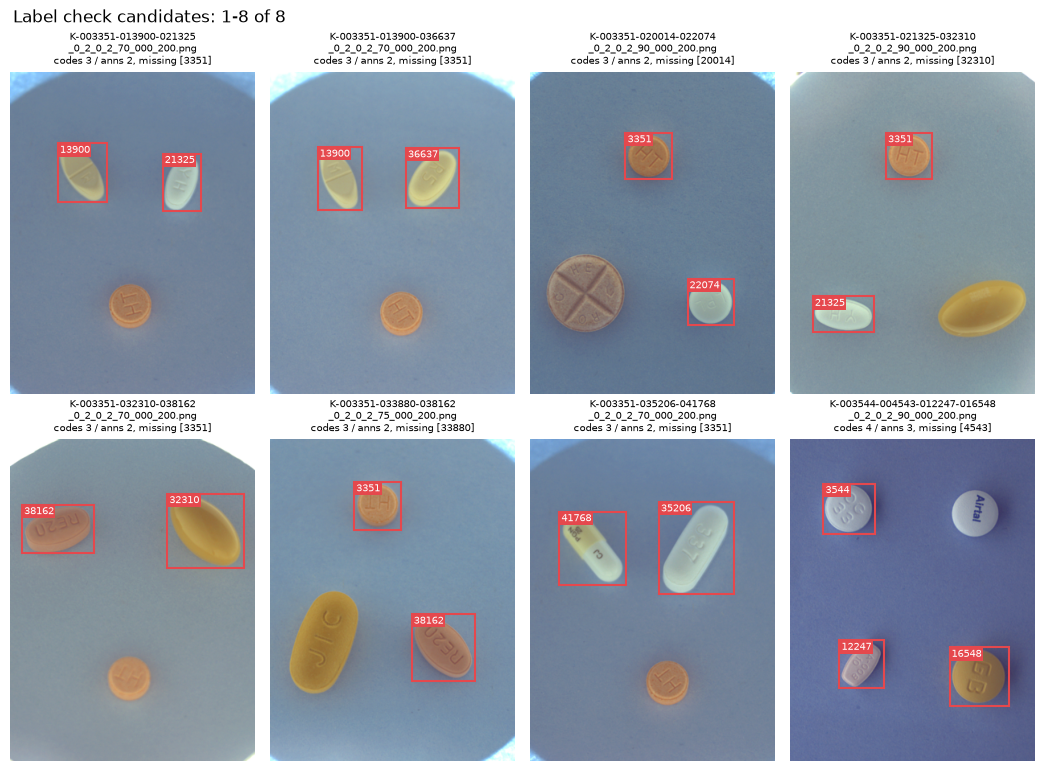

In [96]:
path_by_name = {p.name: p for p in train_img_paths}

def show_thumbs(paths, captions, boxes=None, title="", ncols=4, thumb=400):
    """이미지를 작게 줄여 격자로 보여 준다.

    paths   : 이미지 경로 목록
    captions: 각 이미지 위에 적을 글 목록
    boxes   : 각 이미지에 그릴 bbox 목록. 이미지마다 [(x, y, w, h, 글), ...] 형태이고, 좌표는 원본 픽셀 기준
    thumb   : 줄인 이미지의 긴 변 길이(픽셀). 그리는 시간과 메모리를 줄이기 위해 줄여서 그린다.
    """
    if len(paths) == 0:
        print("그릴 이미지가 없습니다.")
        return

    nrows = (len(paths) + ncols - 1) // ncols
    # squeeze=False: 이미지가 1장이어도 axes를 항상 2차원 배열로 받는다.
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 3.8 * nrows), layout="constrained", squeeze=False)
    for ax in axes.flat:
        ax.axis("off")

    for i, (ax, path) in enumerate(zip(axes.flat, paths)):
        with Image.open(path) as img:
            w, h = img.size                 # 원본 크기 (bbox 좌표의 기준)
            img.thumbnail((thumb, thumb))   # 비율을 유지한 채 긴 변이 thumb 픽셀이 되도록 줄임
            # extent: 줄인 이미지를 원본 크기의 좌표 위에 펼쳐 그린다. 그래서 bbox는 원본 좌표 그대로 그리면 된다.
            ax.imshow(img, extent=(0, w, h, 0))
        ax.set_title(captions[i], fontsize=7)

        if boxes is not None:
            for x, y, bw, bh, label in boxes[i]:
                ax.add_patch(plt.Rectangle((x, y), bw, bh, fill=False, edgecolor="#e5484d", linewidth=1.5))
                # 글자는 박스 안쪽 왼쪽 위에 적어서 사진 밖으로 나가지 않게 한다.
                ax.text(x + 8, y + 8, label, fontsize=7, color="white", va="top",
                        bbox=dict(facecolor="#e5484d", edgecolor="none", pad=1))

    fig.suptitle(title, x=0.01, ha="left")
    plt.show()

def boxes_for(file_name):
    """이미지 하나의 bbox 목록을 show_thumbs에 넘길 형태로 만든다. 형식이 유효한 bbox만 그린다."""
    rows = ann_df[(ann_df["file_name"] == file_name) & ann_df["bbox_ok"]]
    return [(r.bbox_x, r.bbox_y, r.bbox_w, r.bbox_h, str(r.category_id)) for r in rows.itertuples()]


def show_with_boxes(rows, title, ncols=4):
    """img_df의 행들을 받아 bbox를 그린 사진을 보여 준다."""
    show_thumbs(
        paths=[path_by_name[name] for name in rows["file_name"]],
        captions=[
            r.file_name.replace("_", "\n_", 1) + f"\ncodes {r.n_codes} / anns {r.n_anns}, missing {r.missing_codes}"
            for r in rows.itertuples()
        ],
        boxes=[boxes_for(name) for name in rows["file_name"]],
        title=title,
        ncols=ncols,
    )


START = 0   # 몇 번째 후보부터 볼지
PAGE = 12   # 한 번에 볼 사진 수

page_df = cand_df.iloc[START:START + PAGE]
show_with_boxes(page_df, f"Label check candidates: {START + 1}-{START + len(page_df)} of {len(cand_df)}")

## 4-5. 후보가 아닌 사진도 확인

4-3에서 파일명 코드와 어노테이션이 일치한 사진 중 6장을 무작위로 골라 같은 방식으로 그립니다(seed 고정).

파일명 자체가 사진과 다르면(예: 파일명에는 코드가 3개인데 사진에는 알약이 4개) 4-3 비교로는 찾을 수 없습니다. 여기서도 박스 없는 알약이 보이면, 파일명 비교만으로는 부족하다는 뜻이므로 전체 이미지를 확인하는 방법으로 바꿔야 합니다.

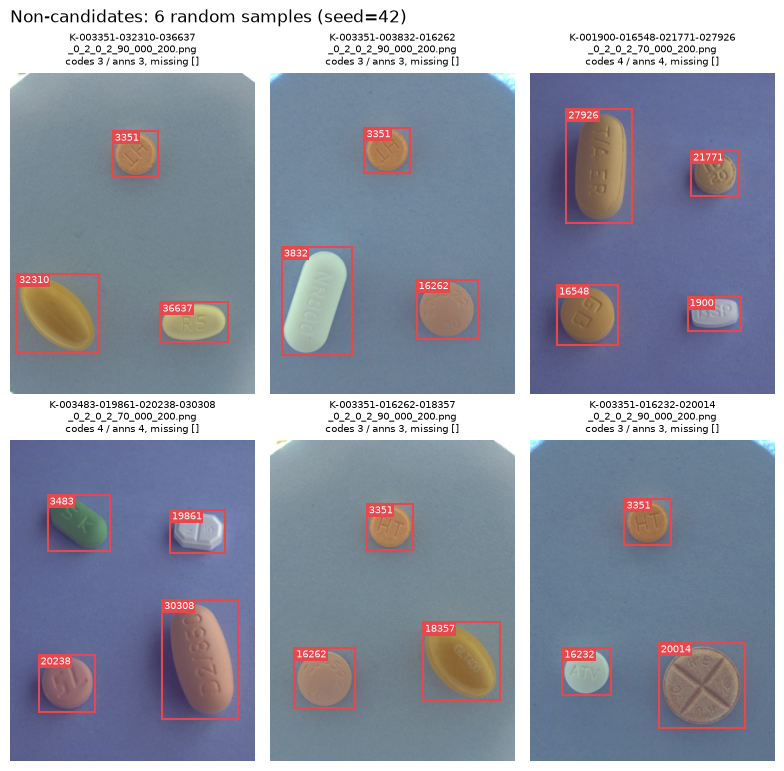

In [97]:
ok_df = img_df.drop(cand_df.index)  # 후보가 아닌 이미지
picked = random.Random(42).sample(list(ok_df.index), min(6, len(ok_df)))
show_with_boxes(ok_df.loc[picked], "Non-candidates: 6 random samples (seed=42)", ncols=3)

## 4-6. 정리

위 출력에서 확인할 것:

- 4-1: 어노테이션 수가 몇 개인 이미지가 많은가
- 4-2: 파일명이 의도대로 나뉘었는가, `category_id`가 파일명 코드 밖에 있는 어노테이션이 있는가
- 4-3: 파일명 코드와 어노테이션이 다른 이미지가 몇 장인가
- 4-4: 후보 사진에 박스가 없는 알약이 실제로 보이는가
- 4-5: 후보가 아닌 사진에도 박스가 없는 알약이 있는가